# CSC173 Fine-Tuning a Pretrained CNN
## Group activity notebook: feature extraction, fine-tuning, and a class-wide experiment

In Lecture 03 you used **MobileNetV2** as a frozen feature extractor. Today your group goes one step further and **fine-tunes** it: you unfreeze part of the pretrained network and keep training it, very gently, on a new dataset. Part 3 is a **challenge: the group with the best test accuracy gets a perfect score.** Everything runs on the **TensorFlow Flowers** dataset: 3,670 color photos of 5 kinds of flowers.

By the end of the period your group should be able to:

1. explain **transfer learning**: what is reused, what is trained, and why it works with little data;
2. choose an **optimizer** and a learning rate, and defend the choice;
3. **read training and validation loss curves** and say whether a model underfits, fits well, overfits or diverges;
4. **recognize overfitting** and name two ways to stop it;
5. **interpret a confusion matrix**: which classes get mixed up, and the precision and recall of a class.

| Part | What happens | Clock (60 min) |
|---|---|---|
| 0–1 | Set up, roles, and the data (all code given: just run it) | 0:00–0:07 |
| 2 | Transfer learning: a frozen MobileNetV2, an **optimizer race**, and **overfitting on purpose** | 0:07–0:22 |
| 3 | 🏆 The **fine-tuning challenge**: tune your own recipe | 0:22–0:40 |
| 4 | Your official test score and the **confusion matrix** | 0:40–0:48 |
| 5 | Leaderboard reveal and a **curve-reading gallery** | 0:48–0:60 |

The Experimenter keeps time. If your group falls behind, skip the ✍️ written answers and come back to them while the next model trains: every training cell gives you a minute or two of waiting.

**How to work:** one notebook per group. Fill in every `# TODO`, run the cells from top to bottom, and answer every ✍️ question in the cell below it. There are only **8 TODO cells**, each a few short lines, and each one prints a `Check:` line that should say `True`. Use a GPU: *Runtime → Change runtime type → T4 GPU* **before** class starts the clock. With a GPU every training cell takes 1 to 2 minutes.

---
## 0. Set up

### 0a. Group roles

Pick one role each before you touch the code. Everyone must be able to explain every cell, but each role owns one job.

| Role | Owns | During the activity |
|---|---|---|
| **Driver** | the keyboard | Types the code and runs the cells. Shares the screen so everyone can see. Does **not** decide alone. |
| **Navigator** | the instructions and the Checks | Reads each step aloud, catches bugs, makes sure every `Check:` says `True` before the group moves on. Leads Part 1. |
| **Experimenter** | the challenge strategy | Leads the group's **plan before each trial** in Part 3, watches the clock, and keeps the trial log. |
| **Reporter** | the answers and the share-out | Types the ✍️ answers, posts the group's results line to the leaderboard, and gives the 45-second share-out in Part 5. |

Groups of 3: the Experimenter is also the Reporter. Groups of 5: two Navigators, one of whom keeps a written log of every error and how you fixed it.

In [23]:
GROUP = 2                     # TODO: your group number from the board (1, 2, 3, ...)
MEMBERS = {                   # TODO: your names
    "Driver":       "Villanueva",
    "Navigator":    "Estrella",
    "Experimenter": "Jagonia",
    "Reporter":     "Macalangan",
}
print(f"Group {GROUP}:", ", ".join(f"{r} {n}" for r, n in MEMBERS.items() if n))
print("Check:", GROUP > 0 and all(MEMBERS[r] for r in ["Driver", "Navigator", "Experimenter"]))

Group 2: Driver Villanueva, Navigator Estrella, Experimenter Jagonia, Reporter Macalangan
Check: True


### 0b. Libraries and the GPU

In [5]:
import os, time, pathlib, tarfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 173
keras.utils.set_random_seed(SEED)      # same random numbers every run, so results are repeatable
print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("T4 GPU")
print("GPU:", gpus if gpus else "none. Use Runtime → Change runtime type → T4 GPU, or training will take about 10 times longer.")

def plot_history(histories, metric="accuracy", title=None, ax=None, boundary=None):
    # Plot training (solid) and validation (dashed) curves for one or more {name: history-dict}.
    ax = ax or plt.gca()
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = np.arange(1, len(h[metric]) + 1)
        ax.plot(epochs, h[metric], color=color, label=f"{name} train")
        ax.plot(epochs, h["val_" + metric], "--", color=color, label=f"{name} val")
    if boundary:
        ax.axvline(boundary + 0.5, color="k", ls=":", lw=1)
        ax.text(boundary + 0.6, ax.get_ylim()[0], " fine-tuning starts", fontsize=8, va="bottom")
    ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.legend(fontsize=8); ax.grid(alpha=.3)
    if title: ax.set_title(title)

TensorFlow 2.22.0-rc1
GPU: none. Use Runtime → Change runtime type → T4 GPU, or training will take about 10 times longer.


---
## 1. The data

*Navigator leads Parts 1 and 2.* The dataset is one folder per class. We download it once (about 220 MB, under a minute on Colab).

In [4]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = keras.utils.get_file("flower_photos.tgz", origin=URL)
data_dir = pathlib.Path("flower_photos")
if not data_dir.exists():
    with tarfile.open(archive) as tar:
        tar.extractall(".")

class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
paths, labels = [], []
for c, name in enumerate(class_names):
    files = sorted((data_dir / name).glob("*.jpg"))
    paths += [str(f) for f in files]
    labels += [c] * len(files)
paths, labels = np.array(paths), np.array(labels)
NUM_CLASSES = len(class_names)
print("classes:", class_names)
print("images per class:", np.bincount(labels), " total:", len(paths))

classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
images per class: [633 898 641 699 799]  total: 3670


### 1a. A stratified split

Given code, exactly as in Lecture 04: shuffle each class separately, then give **15% of every class** to validation, **15%** to the test set, and the rest (70%) to training. The test set is locked away until Part 4.

In [7]:
def stratified_split(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    # Return (train_idx, val_idx, test_idx), each class split in the same proportions.
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        n_val, n_test = int(round(val_frac * len(idx))), int(round(test_frac * len(idx)))
        val_idx.append(idx[:n_val])
        test_idx.append(idx[n_val:n_val + n_test])
        train_idx.append(idx[n_val + n_test:])
    out = [np.concatenate(s) for s in (train_idx, val_idx, test_idx)]
    for s in out:
        rng.shuffle(s)
    return out

tr_idx, va_idx, te_idx = stratified_split(labels)
print("train / val / test sizes:", len(tr_idx), len(va_idx), len(te_idx))
print("val images per class:", np.bincount(labels[va_idx]))
no_overlap = len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(paths)
print("Check:", no_overlap and len(va_idx) == 551 and len(te_idx) == 551)

train / val / test sizes: 2568 551 551
val images per class: [ 95 135  96 105 120]
Check: True


### 1b. Input pipelines

This cell is given. It reads each JPEG, resizes it to **160×160**, and batches 32 images at a time. Pixels stay in 0 to 255 here; the model rescales them itself.

one batch: (32, 160, 160, 3) <dtype: 'float32'>  labels: [4 1 2 0 1 3 4 2 2 1]


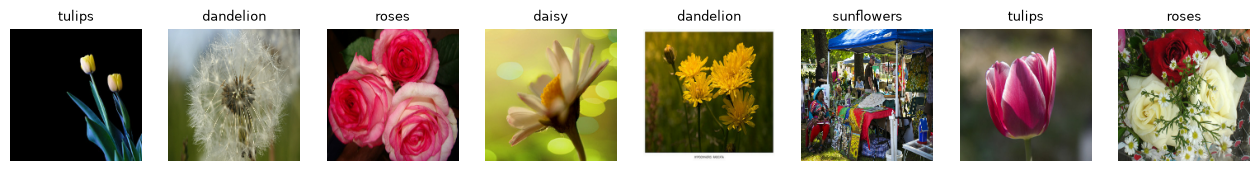

In [8]:
IMG_SIZE = (160, 160)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.uint8), label            # uint8 keeps the cache small

def make_ds(idx, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths[idx], labels[idx]))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(idx), seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = make_ds(tr_idx, shuffle=True)
val_ds   = make_ds(va_idx)
test_ds  = make_ds(te_idx)

xb, yb = next(iter(train_ds))
print("one batch:", xb.shape, xb.dtype, " labels:", yb[:10].numpy())
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, y in zip(axes, xb[:8], yb[:8]):
    ax.imshow(img.numpy().astype("uint8")); ax.set_title(class_names[int(y)], fontsize=9); ax.axis("off")
plt.show()

✍️ **Question 1.** (a) What accuracy would a model get by always predicting the largest class? That is the baseline every result today must beat. (b) Why must the test set stay locked until Part 4, even though we already have a validation set?

*Your answer:*

a) The model's accuracy would adopt the class percentage of said largest class which is the dandelion class of approximately 24.5% of the total population.

b) The test set must remain locked until part 4 such that they will be isolated from the training set throughout the whole process. 

---
## 2. Stage 1: feature extraction

MobileNetV2 was trained on 1.4 million ImageNet photos. We keep its convolutional **base**, throw away its 1,000-class head, and put a new head for our 5 classes on top.

```
input 160×160×3 → augmentation → rescale to [−1, 1] → MobileNetV2 base (frozen) → global average pool → dropout → Dense(5, softmax)
```

### 2a. Build the model

In [9]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_model(pretrained=True):
    # Return (model, base). pretrained=False gives the same network with random weights.
    base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False,
                                          weights="imagenet" if pretrained else None)
    base.trainable = False
    inputs = keras.Input(IMG_SIZE + (3,))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # MobileNetV2 expects pixels in [−1, 1]
    # training=False keeps the base's BatchNorm layers in inference mode, even later when we unfreeze them.
    # A network trained from scratch needs its BatchNorm statistics to learn, so it gets training=None.
    x = base(x, training=False if pretrained else None)
    x = layers.GlobalAvgPool2D()(x) # TODO: GlobalAveragePooling2D, turns 5×5×1280 feature maps into a 1280 vector
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x) # TODO: a Dense layer with NUM_CLASSES units and softmax
    return keras.Model(inputs, outputs), base

def count_params(weights):
    return sum(int(np.prod(w.shape)) for w in weights) # TODO: total number of numbers in a list of weight tensors (np.prod of each shape)

keras.utils.set_random_seed(SEED)
model, base = build_model()
n_train, n_total = count_params(model.trainable_weights), count_params(model.weights)
print(f"base layers: {len(base.layers)} · trainable parameters: {n_train:,} of {n_total:,} ({100 * n_train / n_total:.2f}%)")
print("Check:", n_train == 1280 * NUM_CLASSES + NUM_CLASSES and n_total == model.count_params())

base layers: 154 · trainable parameters: 6,405 of 2,264,389 (0.28%)
Check: True


### 2b. The base as a feature extractor

While the base is frozen it never changes, so we can run every photo through it **once** and keep the 1,280 numbers it produces per photo. Training a head on these saved features takes seconds, which lets us run quick experiments in 2c and 2d. (No augmentation here: each photo gives one fixed feature vector.)

In [8]:
feature_extractor = keras.Sequential([layers.Input(IMG_SIZE + (3,)), layers.Rescaling(1 / 127.5, offset=-1),
                                      base, layers.GlobalAveragePooling2D()])
t0 = time.time()
F_train = feature_extractor.predict(make_ds(tr_idx), verbose=0)
F_val   = feature_extractor.predict(val_ds, verbose=0)
y_tr, y_va = labels[tr_idx], labels[va_idx]
print(f"features: train {F_train.shape}, val {F_val.shape} in {time.time() - t0:.0f} s")

def head_model(hidden=0, dropout=0.0):
    # A head that works on the saved 1,280-number features. hidden > 0 adds two big hidden layers.
    m = keras.Sequential([layers.Input((1280,))])
    for _ in range(2 if hidden else 0):
        m.add(layers.Dense(hidden, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return m

features: train (2568, 1280), val (551, 1280) in 22 s


### 2c. Which optimizer? A race

Same head, same features, same 15 epochs, the **same learning rate** ($10^{-3}$), four optimizers. Only the optimizer changes.

| Optimizer | Keras | Idea from the lecture |
|---|---|---|
| SGD | `keras.optimizers.SGD(1e-3)` | step straight down the gradient |
| SGD + momentum | `keras.optimizers.SGD(1e-3, momentum=0.9)` | keep a running velocity, so steps build up in a consistent direction |
| RMSprop | `keras.optimizers.RMSprop(1e-3)` | divide each step by a running size of that weight's gradients |
| Adam | `keras.optimizers.Adam(1e-3)` | momentum + RMSprop, with bias correction |

SGD           val loss after 1 epoch 1.342 · after 5 0.753 · after 15 0.507 · lowest 0.507 at epoch 15
SGD+higherlr+momentum val loss after 1 epoch 1.495 · after 5 0.343 · after 15 0.354 · lowest 0.343 at epoch 6
SGD+lowerlrlr+momentum val loss after 1 epoch 1.632 · after 5 0.773 · after 15 0.499 · lowest 0.499 at epoch 15
SGD+momentum  val loss after 1 epoch 0.586 · after 5 0.378 · after 15 0.315 · lowest 0.315 at epoch 15
SGD+lowermomentum val loss after 1 epoch 1.152 · after 5 0.620 · after 15 0.437 · lowest 0.437 at epoch 15
RMSprop       val loss after 1 epoch 0.498 · after 5 0.328 · after 15 0.336 · lowest 0.314 at epoch 9
Adam          val loss after 1 epoch 0.475 · after 5 0.333 · after 15 0.312 · lowest 0.311 at epoch 13


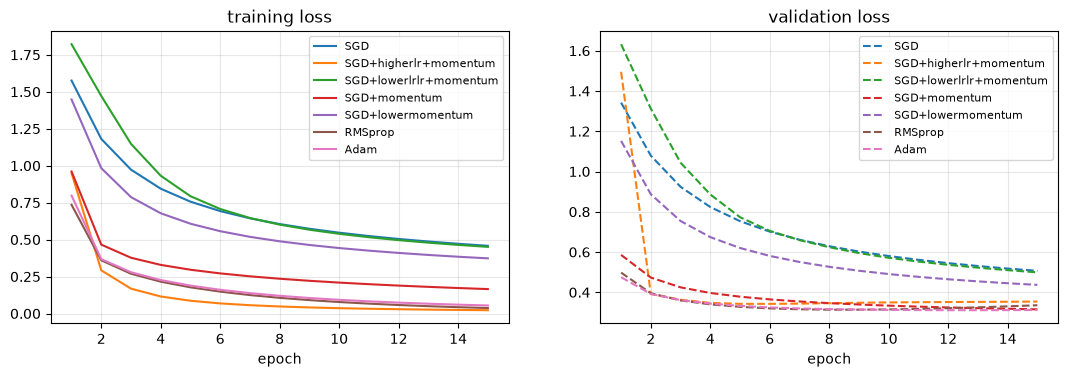

Check: True


In [9]:
def make_optimizers():
    return {
        "SGD":          keras.optimizers.SGD(1e-3),   # TODO
        "SGD+higherlr+momentum":          keras.optimizers.SGD(1e-1),   # TODO
        "SGD+lowerlrlr+momentum":          keras.optimizers.SGD(1e-5, momentum=0.99),   # TODO
        "SGD+momentum": keras.optimizers.SGD(1e-3, momentum=0.9),   # TODO
        "SGD+lowermomentum": keras.optimizers.SGD(1e-3, momentum=0.4),   # TODO
        "RMSprop":      keras.optimizers.RMSprop(1e-3),   # TODO
        "Adam":         keras.optimizers.Adam(1e-3),   # TODO
    }

race = {}
for name, opt in make_optimizers().items():
    keras.utils.set_random_seed(SEED)
    m = head_model()
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    race[name] = m.fit(F_train, y_tr, validation_data=(F_val, y_va), epochs=15, batch_size=BATCH, verbose=0).history
    v = race[name]["val_loss"]
    print(f"{name:13s} val loss after 1 epoch {v[0]:.3f} · after 5 {v[4]:.3f} · after 15 {v[-1]:.3f} · lowest {min(v):.3f} at epoch {int(np.argmin(v)) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, h), color in zip(race.items(), plt.cm.tab10.colors):
    axes[0].plot(np.arange(1, 16), h["loss"], color=color, label=name)
    axes[1].plot(np.arange(1, 16), h["val_loss"], "--", color=color, label=name)
for ax, t in zip(axes, ["training loss", "validation loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()
print("Check:", min(race["Adam"]["val_loss"]) < min(race["SGD"]["val_loss"]))

✍️ **Question 2.** (a) Rank the four optimizers by how fast the validation loss falls. Which would you choose as your default, and why? (b) Plain SGD is the slowest here. Name two things you could change to make it competitive. (c) For the fastest optimizers, the validation loss reaches its lowest point and then creeps back up while the training loss keeps falling. What is that called, and what would you do about it? (d) This head is all that stage 1 of transfer learning trains: 6,405 of 2.26 million parameters. Why does a frozen base trained on ImageNet still give good features for flowers?

*Your answer:*

a) The SGD optimizer ranks first as the fastest fall in their validation loss, beginning at more than 1.2 then dropping to 0.5 at 14 epochs. However, it still procured the greatest loss throughout its whole lifetime as compared to the other optimizers. This is followed by SGD+momentum, Then RMSprop and then closely by Adam. Furthermore, we have also observed that the validation loss of RMSprop began to diverge and thus increase at epochs > 10. As default, the Adam optimizer would be used. Despite its validation loss slowly decreasing, this behavior would be understandable as it readily began at low validation losses.
b) Default SGD may be further enhanced by increasing its learning rate and to train it for more epochs, however, it must be noted that granting it higher momentum values might make its learning more erratic and thus diverge much faster, significantly increasing its validation loss early on in the epochs. As such, an optimal method of enhancing the default SGD would be to have increased learning rate. Additionally, although this method would significantly expedite the fall of its validation loss, it would begin diverging to higher validation loss with further epochs due to overfitting.
c) This observation is due to overfitting wherein the model have learned to incorporate bias due to memorization of the training set. this may be mitigated by allowing the model to learn at lower rates.
d) Because these base models have already been pretrained sufficiently and thus, the model is readily knowledgable and already possesses tuned weights.

### 2d. Overfitting on purpose

Now break it. A **big** head (two hidden layers of 512, about 920,000 parameters) trained on only **10 photos per class** for 150 epochs. Then the same head with **dropout and early stopping**. Watch the two loss curves separate.

big head, no regularization   : epochs run 150 · train acc 1.000 · val loss at the last epoch 0.920 · lowest val loss 0.752 at epoch 3
dropout 0.5 + early stopping  : epochs run  20 · train acc 1.000 · val loss at the last epoch 0.799 · lowest val loss 0.730 at epoch 10


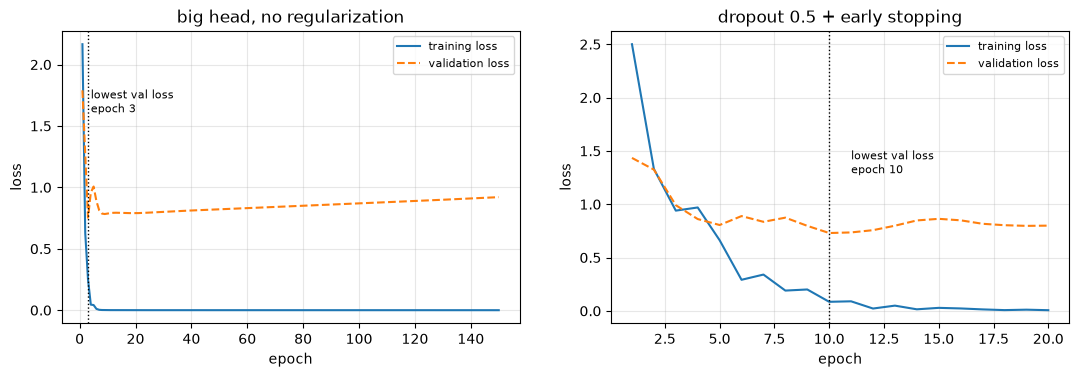

Check: True


In [10]:
rng = np.random.default_rng(SEED)
few = np.concatenate([rng.choice(np.where(y_tr == c)[0], 10, replace=False) for c in range(NUM_CLASSES)])

def fit_head(model, callbacks=None):
    keras.utils.set_random_seed(SEED)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(F_train[few], y_tr[few], validation_data=(F_val, y_va), epochs=150,
                     batch_size=16, callbacks=callbacks or [], verbose=0).history

h_overfit = fit_head(head_model(hidden=512))
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
h_regular = fit_head(head_model(hidden=512, dropout=0.5), [early_stop])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, h) in zip(axes, [("big head, no regularization", h_overfit), ("dropout 0.5 + early stopping", h_regular)]):
    best = int(np.argmin(h["val_loss"]))
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="training loss")
    ax.plot(np.arange(1, len(h["loss"]) + 1), h["val_loss"], "--", label="validation loss")
    ax.axvline(best + 1, color="k", ls=":", lw=1); ax.text(best + 2, max(h["val_loss"]) * 0.9, f"lowest val loss\nepoch {best + 1}", fontsize=8)
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    print(f"{name:30s}: epochs run {len(h['loss']):3d} · train acc {h['accuracy'][-1]:.3f} · val loss at the last epoch {h['val_loss'][-1]:.3f}"
          f" · lowest val loss {min(h['val_loss']):.3f} at epoch {best + 1}")
plt.show()
print("Check:", isinstance(early_stop, keras.callbacks.EarlyStopping) and len(h_regular["loss"]) < 150)

✍️ **Question 3: reading the curves.** (a) In the left plot, at which epoch does the model start to overfit? Give two signs in the plot that tell you so. (b) Training accuracy is near 100% at the end. Why is that *not* good news? (c) Early stopping keeps the weights from the best epoch. Compare the validation loss of the model you would keep in each plot. Did regularization make 50 photos as good as 2,568? Name one other way to fight overfitting (hint: Part 2e uses it, and the best one is not a layer at all).

*Your answer:*

a) The model starts overfitting at epoch 20 wherein its validation loss is at the lowest.

b) This means that the model have already memorized the training set and now bases its predictions of it rather than inferred characteristics and vectors.

c) As can be seen in the plots, the model with the big head trained on the same 10 photos over 150 epochs exhibited a sudden drop in training and validation loss. Moreover, the training loss have quickly zeroed out. This behavior is representative of overfitting and the model has definitely achieved zero training loss due to memorization. AS can be seen, this has caused the validation loss for this model to diverge. Conversely, the second model which we would keep exhibited a gradual decline in both losses. Although this took significantly more time, it achieved a much lesser validation loss. The employed regularization trained the model to rely on characteristic features rather than heavily relying on the same combinations of activations every time. As such, overfitting is effectively curbed. Further regularization may be applied to lessen the probability of overfitting such as randomly applying rotations, flips, and zooms during training.

### 2e. Stage 1 on the full model

Back to the full model with augmentation (random flips, rotations and zooms: a regularizer that creates new versions of each photo every epoch). Five epochs with **Adam at $10^{-3}$**, the winner of the race. Only the 6,405 head parameters change. We save the weights so that Part 3 always starts from this exact model, even if you run Part 3 twice.

Epoch 1/5


c:\Users\Yelfia\Documents\DeepLearning\csc173-1s-2026\csc173-1s-2026-villanueva\activities\04\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 - 22s - 272ms/step - accuracy: 0.6593 - loss: 0.8959 - val_accuracy: 0.8258 - val_loss: 0.5080
Epoch 2/5
81/81 - 18s - 219ms/step - accuracy: 0.8458 - loss: 0.4447 - val_accuracy: 0.8548 - val_loss: 0.4060
Epoch 3/5
81/81 - 18s - 222ms/step - accuracy: 0.8699 - loss: 0.3657 - val_accuracy: 0.8711 - val_loss: 0.3797
Epoch 4/5
81/81 - 18s - 225ms/step - accuracy: 0.8886 - loss: 0.3198 - val_accuracy: 0.8639 - val_loss: 0.3797
Epoch 5/5
81/81 - 18s - 222ms/step - accuracy: 0.9023 - loss: 0.2870 - val_accuracy: 0.8784 - val_loss: 0.3474
stage 1 done in 94 s · validation accuracy 0.878


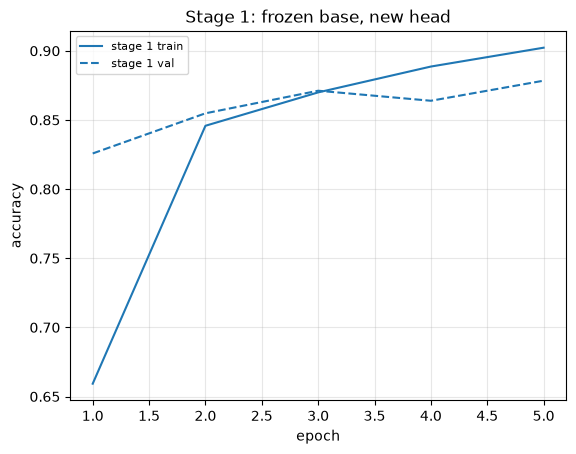

Check: True


In [11]:
WARMUP_EPOCHS = 5
FT_EPOCHS = 5
WARMUP_FILE = "warmup.weights.h5"

def compile_model(model, lr, optimizer="adam"):
    opt = keras.optimizers.Adam(lr) if optimizer == "adam" else keras.optimizers.SGD(lr, momentum=0.9)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

compile_model(model, 1e-3)
t0 = time.time()
warmup = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS, verbose=2).history
warmup_time = time.time() - t0
model.save_weights(WARMUP_FILE)
warmup_val_acc = warmup["val_accuracy"][-1]
print(f"stage 1 done in {warmup_time:.0f} s · validation accuracy {warmup_val_acc:.3f}")
plot_history({"stage 1": warmup}, "accuracy", "Stage 1: frozen base, new head"); plt.show()
print("Check:", warmup_val_acc > 0.80)

---
## 3. The fine-tuning challenge 🏆

Fine-tuning means: **unfreeze** some of the top layers of the base and keep training them together with the head, usually with a **much smaller learning rate**, so the pretrained features adapt to flowers without being destroyed.

Now it is a competition. **The group with the highest test accuracy gets a perfect score (20/20) for this activity.** Every other group is graded with the rubric.

### 3a. Write the unfreeze function

In [10]:
def set_fine_tune(base, n_unfrozen=None):
    # Make the last n_unfrozen layers of the base trainable and freeze all the others.
    # n_unfrozen=None unfreezes the whole base; n_unfrozen=0 keeps it fully frozen.
    base.trainable = True
    n = len(base.layers) if n_unfrozen is None else n_unfrozen
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= (len(base.layers) - n)

# test it on a throwaway copy
_, test_base = build_model()
set_fine_tune(test_base, 30)
flags = [l.trainable for l in test_base.layers]
print(f"unfrozen layers: {sum(flags)} of {len(flags)} · first unfrozen layer: {test_base.layers[flags.index(True)].name}")
ok_30 = flags == [False] * (len(flags) - 30) + [True] * 30
set_fine_tune(test_base, None); ok_all = all(l.trainable for l in test_base.layers)
set_fine_tune(test_base, 0);    ok_none = not any(l.trainable for l in test_base.layers)
print("Check:", ok_30 and ok_all and ok_none)

unfrozen layers: 30 of 154 · first unfrozen layer: block_13_project_BN
Check: True


### 3b. Challenge rules

*Experimenter leads this part.*

**Your knobs** (a *recipe*):

| Knob | Allowed values | What it controls |
|---|---|---|
| `unfreeze` | `0` to `154`, or `None` for all | how many of the top layers of the base are trained |
| `optimizer` | `"adam"`, `"rmsprop"`, `"sgd"` (SGD with momentum 0.9) | how each gradient becomes a step |
| `lr` | any positive number | the learning rate |
| `epochs` | `1` to `10` | fine-tuning epochs for this trial |
| `early_stopping` | `True` / `False` | stop when the validation loss stops improving (patience 2) and keep the best epoch |

**Fixed for everyone:** the data, the split, the seed, the model, and the stage 1 weights from Part 2e. Every trial starts again from those weights.

1. **Try as many recipes as you have time for** in 3d. Each trial takes about 1 to 2 minutes on a T4 GPU. Most groups fit 3 to 5.
2. **Your entry is chosen for you:** the trial with the highest **validation** accuracy. You never pick by looking at the test set.
3. **The test set is used once**, in Part 4a. The official score cell counts its runs. An entry whose score was computed more than once cannot win (it is still graded normally).
4. **Ties:** every group tied for first (to 3 decimals) gets the perfect score.
5. The instructor may re-run the winning notebook from top to bottom. The test accuracy must come out within 0.02 of the one on the leaderboard (GPUs are not perfectly repeatable).
6. Don't change the given code (split, data, model, `try_recipe`). Changing it disqualifies the entry.

✍️ **Question 4: plan before you run.** Before your first trial, write down your first recipe and one reason for **each** knob, using what you saw in Part 2 (the optimizer race, the overfitting plot) and the lecture. The Experimenter writes it; it is graded on reasoning.

*Your answer:*

try_recipe(unfreeze=30, optimizer="adam", lr=1e-3, epochs=7, early_stopping=True)

To our prior understanding, this model have already been sufficiently trained and is thus knoweldgable on the flowers and their corresponding features. The code however wishes to train the model on classifying the set five flower classes. In respect of its prior training, and in consideration of the need to learn the new imposed classifications, we have chosen a balanced scale of 30 layers to unfreeze for further training. 

As has been shown in 2c, Adam compounds a running average of the gradient with a running average of its size. This is a shared feature with RMSprop, however, Adam also employed bias correction. Consequently, Adam has consistently achieved the lowest (or second to being the lowest) in the race in 2c. It effectively reached low validation loss on earlier epochs and has exhibited little to no divergence in later epochs. As such, this has been chosen as the optimizer.

Throughout previous cells, the learning rates of the model have been set at 1e-3. We have retained assumptions that adjusting the learning rate would prove to be critical in perfecting the optimal training configuration for the model. However, we have decided that we ought to set a base first to which subsequent trials would then possess variations in their learning rates, and epochs. 

The team has expressed curiosities in the effect of epochs as well and have retained an agreement that having more epochs would allow us to observe more behaviors that may be used in formulating subsequent trials. We have also retained the idea that regardless of how long the model trains, we would have enabled early stopping such as to extract the lowest achieved validation loss anyways. Considering the initial time constraints imposed and the recognition of the need of running multiple trials to find the best configuration, we would not want each trial to run too long. As such, the team have agreed on a sufficiently large 7 epochs and an enabled early stopping.

### 3c. The trial runner

Given code. `try_recipe` trains one recipe from the stage 1 weights, logs it in `TRIALS`, and keeps the model if it is your best so far on validation. It never touches the test set.

In [11]:
TRIALS = []                      # one row per trial
ENTRY = {"val_acc": -1}          # your best trial so far, by validation accuracy
ALLOWED_OPT = {"adam", "rmsprop", "sgd"}

def compile_model(model, lr, optimizer="adam"):
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda lr: keras.optimizers.SGD(lr, momentum=0.9)}[optimizer](lr)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=5, early_stopping=False, verbose=0):
    assert optimizer in ALLOWED_OPT and 1 <= epochs <= 10 and lr > 0 and (unfreeze is None or 0 <= unfreeze <= 154)
    keras.utils.set_random_seed(SEED)
    model, base = build_model()
    model.load_weights(WARMUP_FILE)                    # every trial starts from stage 1
    set_fine_tune(base, unfreeze)
    compile_model(model, lr, optimizer)                # recompile so the new trainable flags take effect
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)] if early_stopping else []
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=verbose).history
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)    # the weights we actually keep
    history = {k: warmup[k] + h[k] for k in warmup}         # stage 1 + stage 2, for the plots
    row = dict(trial=len(TRIALS) + 1, unfreeze=unfreeze, optimizer=optimizer, lr=lr, epochs_run=len(h["loss"]),
               early_stopping=early_stopping, trainable=count_params(model.trainable_weights),
               val_acc=val_acc, val_loss=val_loss, seconds=time.time() - t0, history=history)
    TRIALS.append(row)
    if val_acc > ENTRY["val_acc"]:
        ENTRY.clear(); ENTRY.update(row, model=model)

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    plot_history({f"trial {row['trial']}": history}, "loss", f"trial {row['trial']}: loss", axes[0], WARMUP_EPOCHS)
    plot_history({f"trial {row['trial']}": history}, "accuracy", "accuracy", axes[1], WARMUP_EPOCHS)
    plt.show()
    show_trials()

def show_trials():
    print(f"{'trial':>5} {'unfreeze':>8} {'optimizer':>9} {'lr':>8} {'epochs':>6} {'early':>5} {'trainable':>10} {'val_acc':>7} {'val_loss':>8} {'time':>6}")
    for r in sorted(TRIALS, key=lambda r: -r["val_acc"]):
        mark = "  ← your entry" if r["trial"] == ENTRY.get("trial") else ""
        print(f"{r['trial']:>5} {str(r['unfreeze']):>8} {r['optimizer']:>9} {r['lr']:>8.0e} {r['epochs_run']:>6} {str(r['early_stopping']):>5} "
              f"{r['trainable']:>10,} {r['val_acc']:>7.3f} {r['val_loss']:>8.3f} {r['seconds']:>5.0f}s{mark}")

### 3d. Your trials

Edit the recipe and run the cell again for each new trial. Watch the curves: if the validation loss jumps up when fine-tuning starts, the learning rate is too big; if nothing moves, it is too small or too few layers are unfrozen; if training loss keeps falling while validation loss rises, you are overfitting.

A safe starting point is `unfreeze=30, optimizer="adam", lr=1e-5, epochs=5`. You can do better.

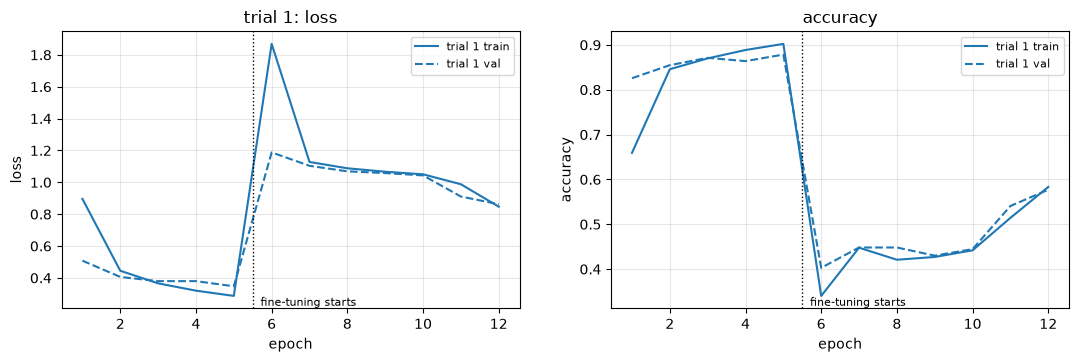

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s  ← your entry


In [14]:
try_recipe(unfreeze=30, optimizer="adam", lr=1e-3, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4

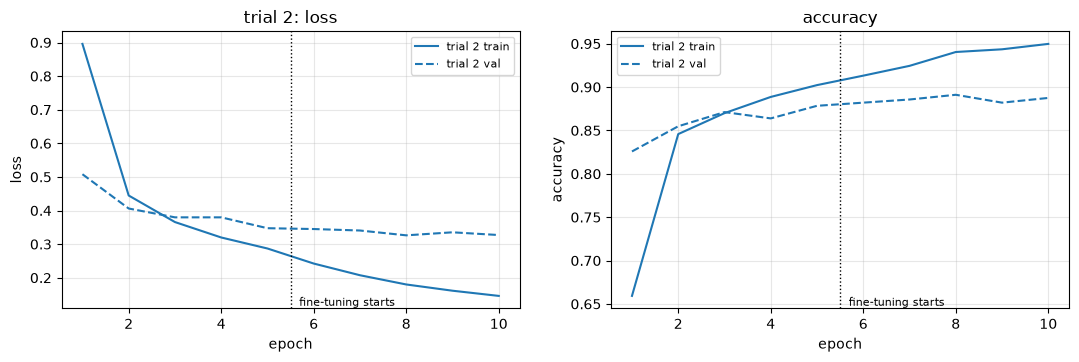

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s


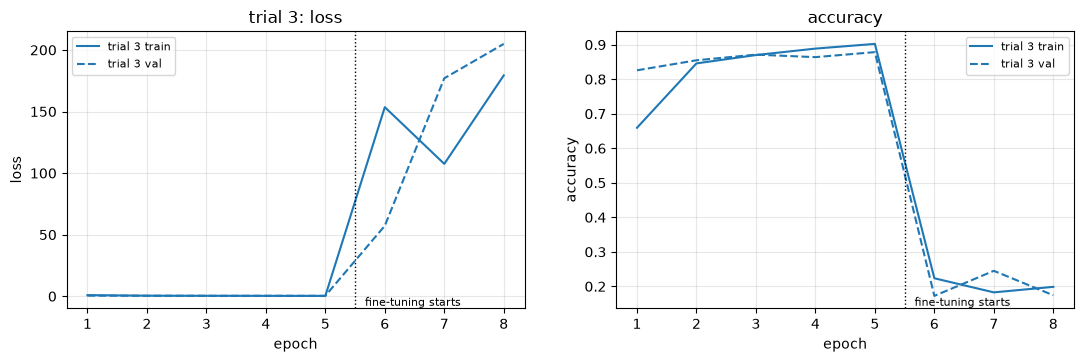

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


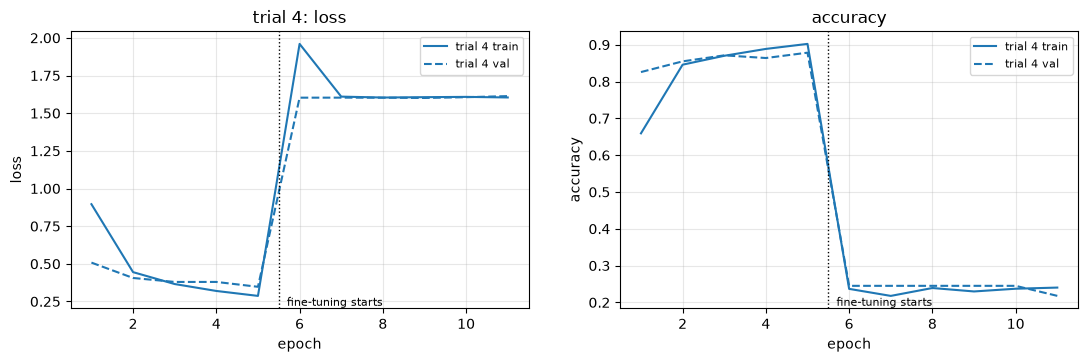

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


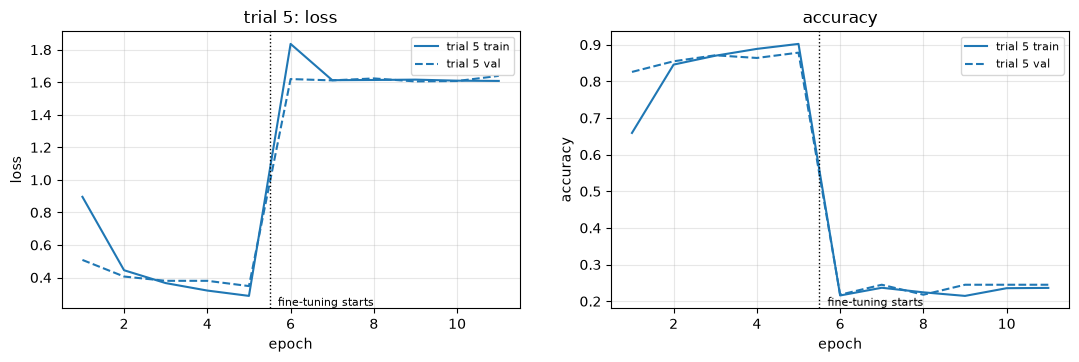

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


In [15]:
try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-1, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=50, optimizer="adam", lr=1e-3, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=100, optimizer="adam", lr=1e-3, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4

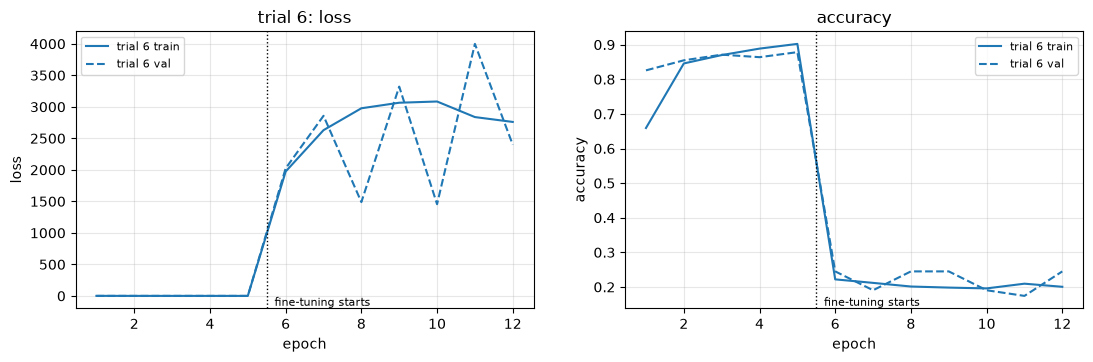

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


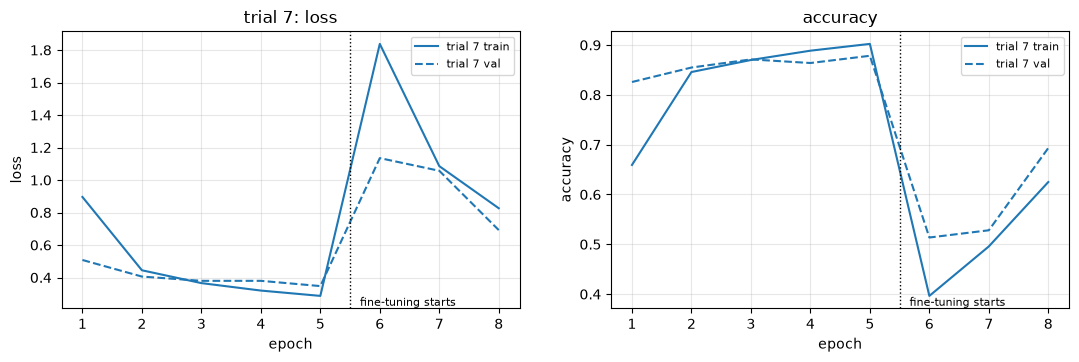

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


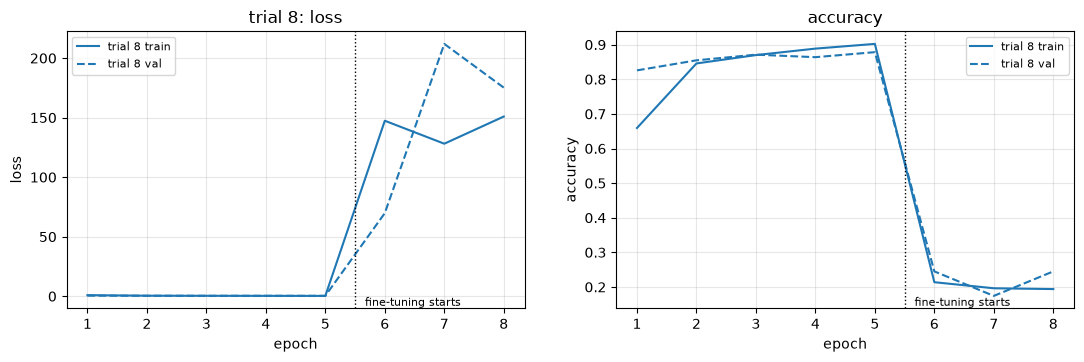

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


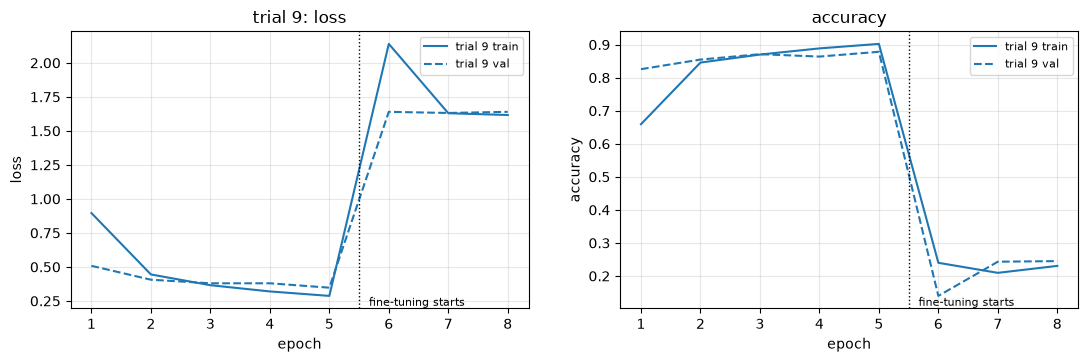

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    9       20      adam    1e-03      3 False  1,212,485   0.245    1.640    72s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


In [16]:
try_recipe(unfreeze=30, optimizer="sgd", lr=1e-1, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-3, epochs=3, early_stopping=False)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-1, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=20, optimizer="adam", lr=1e-3, epochs=3, early_stopping=False)   # TODO: your recipe from Question 4

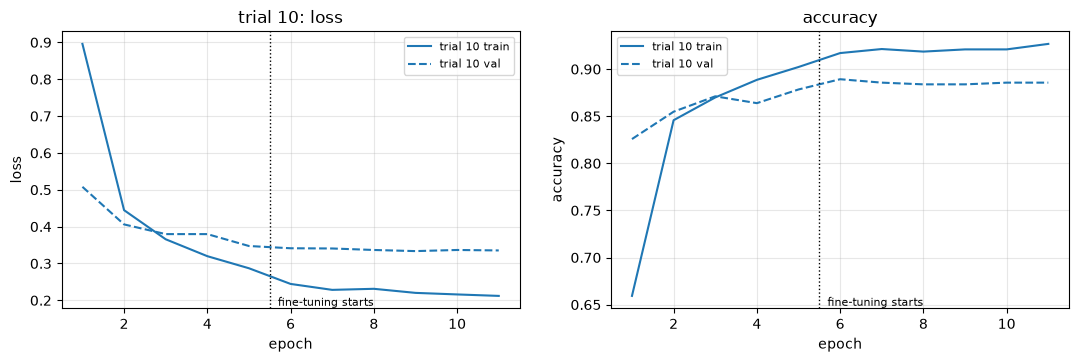

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    9       20      adam    1e-03      3 False  1,212,485   0.245    1.640    72s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


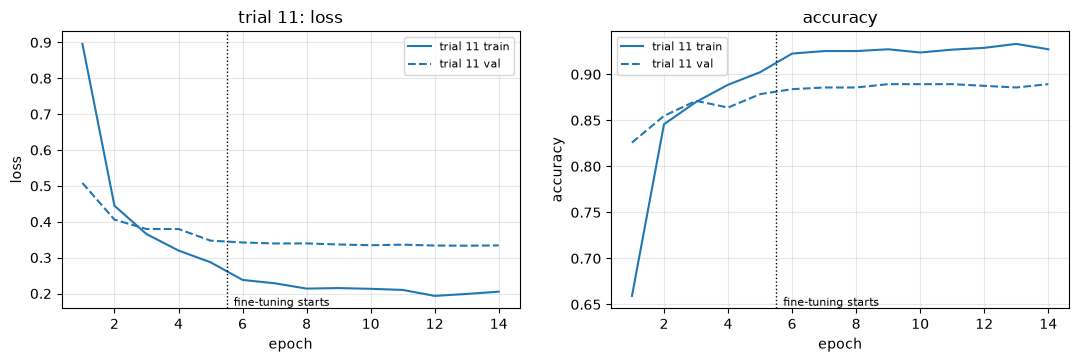

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    9       20      adam    1e-03      3 False  1,212,485   0.245    1.640    72s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
    3       30      adam    1e-01      3  True  1,532,805   0.172   57.218    76s


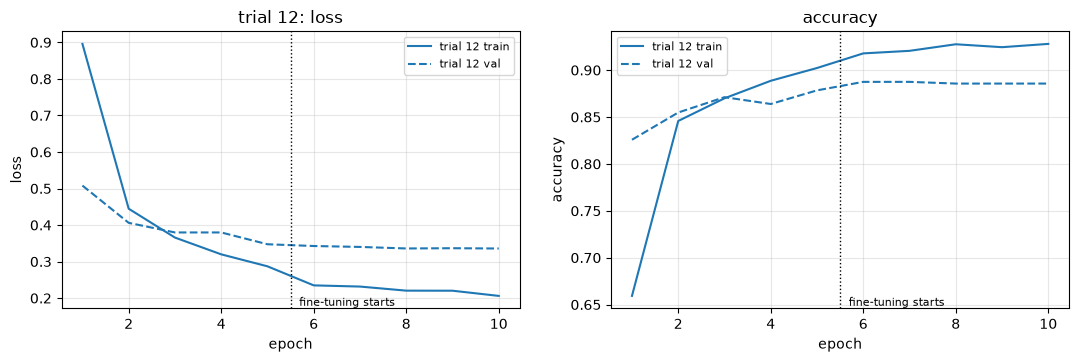

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    9       20      adam    1e-03      3 False  1,212,485   0.245    1.640    72s
    6       30       sgd    1e-01      7  True  1,532,805   0.191 1455.083   162s
  

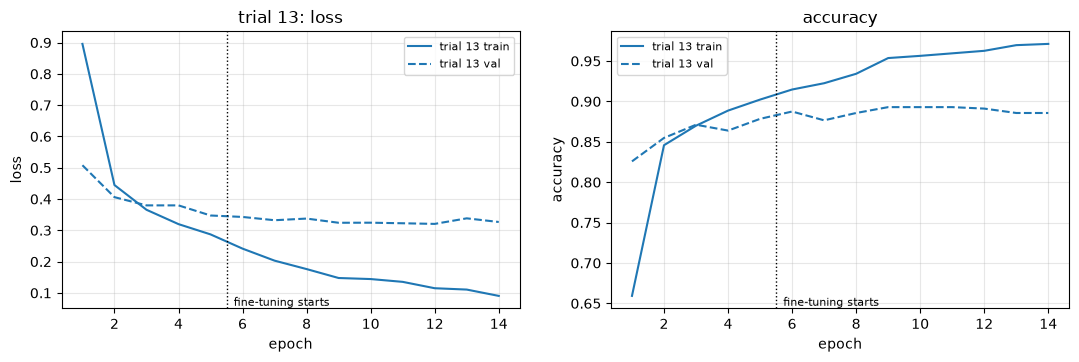

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
    9       20      adam    1e-03      3 False  1,212,485   0.245    1.640    72s
  

In [17]:
try_recipe(unfreeze=30, optimizer="adam", lr=1e-6, epochs=7, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-6, epochs=5, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=30, optimizer="adam", lr=1e-5, epochs=10, early_stopping=True)   # TODO: your recipe from Question 4

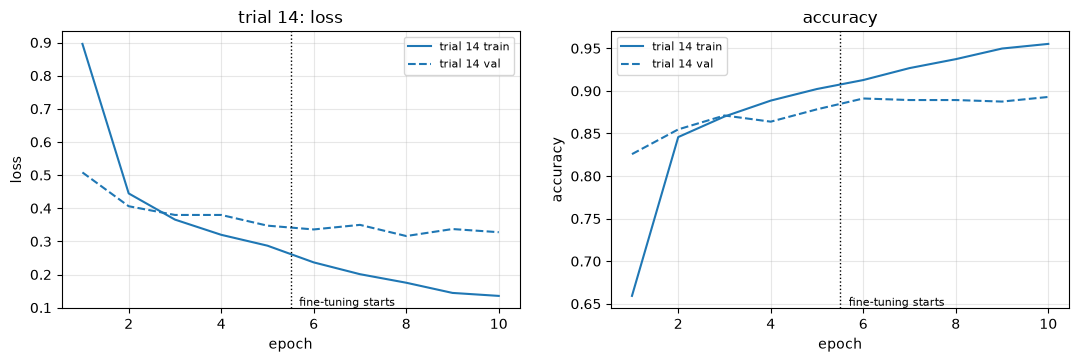

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
    8       30      adam    1e-01      3  True  1,532,805   0.245   69.806    78s
  

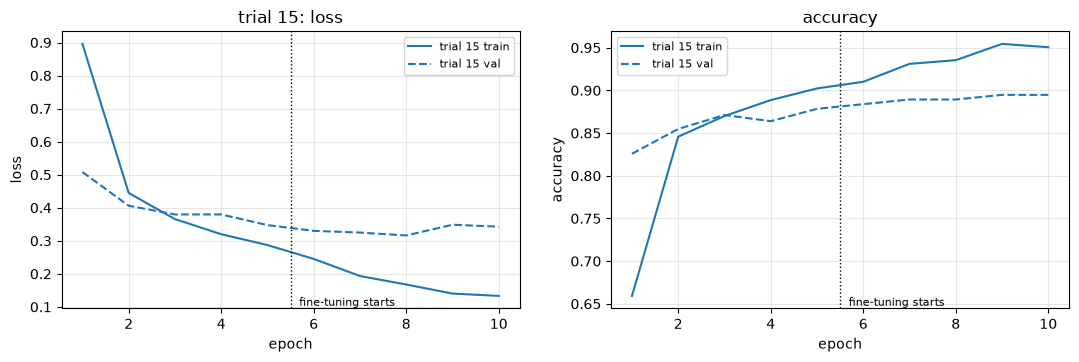

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s  ← your entry
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
    5      100      adam    1e-03      6  True  2,174,789   0.245    1.605   179s
  

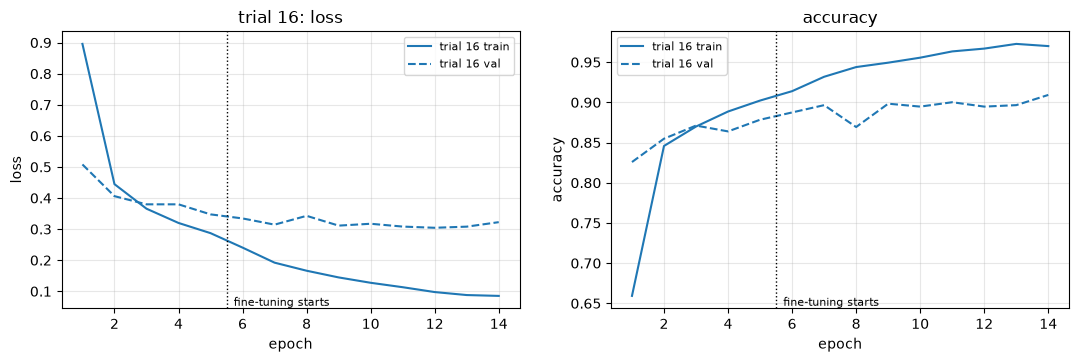

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s  ← your entry
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
    4       50      adam    1e-03      6  True  1,861,509   0.245    1.601   142s
  

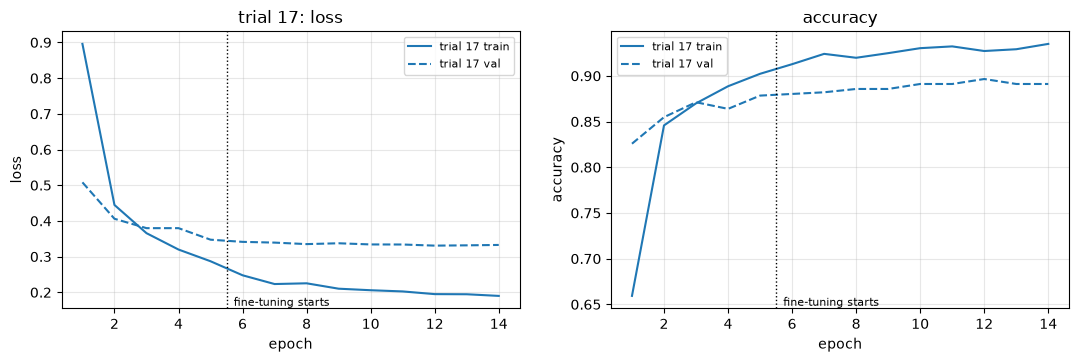

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
    1       30      adam    1e-03      7  True  1,532,805   0.577    0.863   144s
  

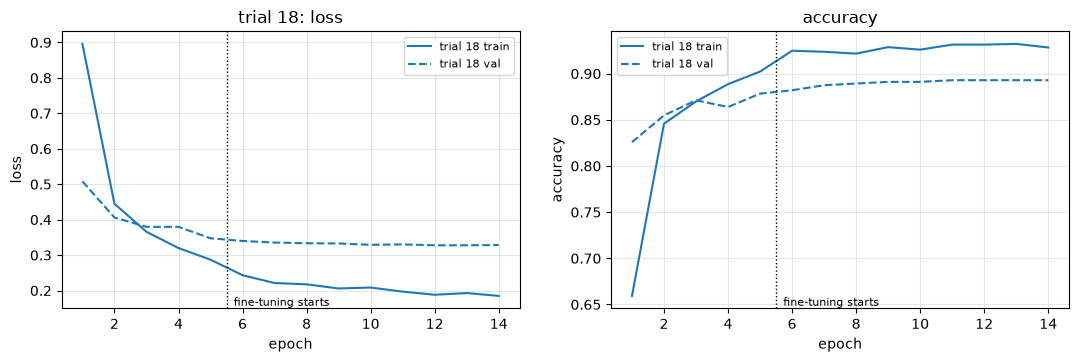

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
    7       30      adam    1e-03      3 False  1,532,805   0.693    0.692    74s
  

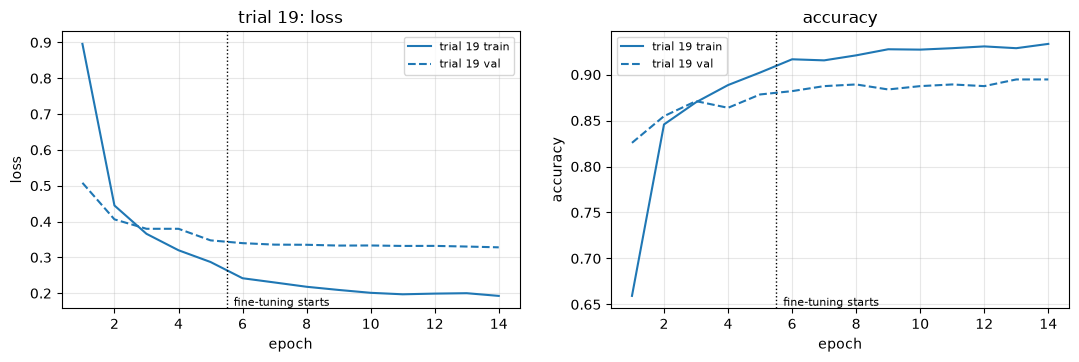

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
  

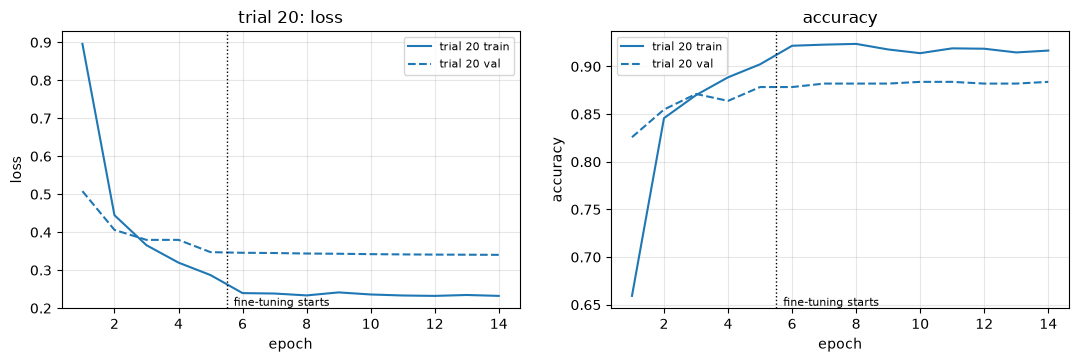

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   10       30      adam    1e-06      6  True  1,532,805   0.884    0.334   131s
  

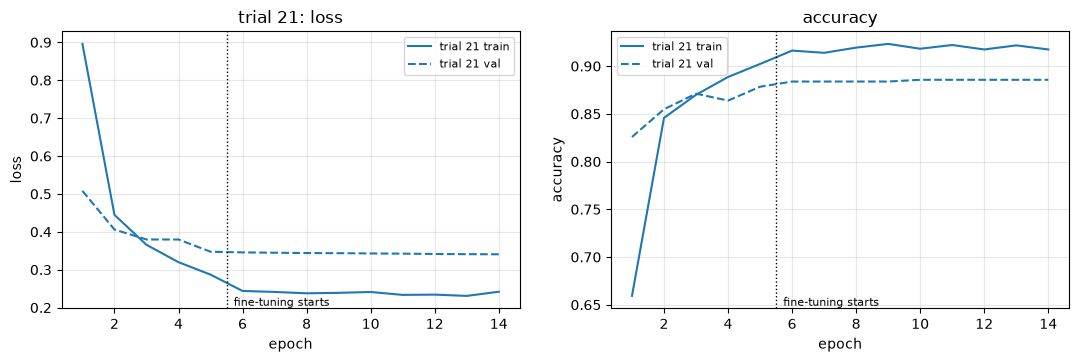

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   21       50      adam    1e-07      9  True  1,861,509   0.886    0.341   182s
  

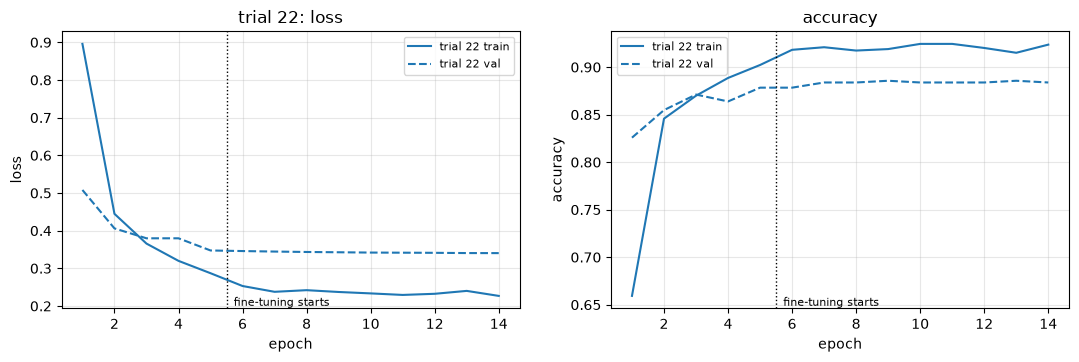

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
   21       50      adam    1e-07      9  True  1,861,509   0.886    0.341   182s
  

In [19]:
try_recipe(unfreeze=40, optimizer="adam", lr=1e-5, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=50, optimizer="adam", lr=1e-5, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=60, optimizer="adam", lr=1e-5, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4

try_recipe(unfreeze=40, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=50, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=60, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4

try_recipe(unfreeze=40, optimizer="adam", lr=1e-7, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=50, optimizer="adam", lr=1e-7, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4
try_recipe(unfreeze=60, optimizer="adam", lr=1e-7, epochs=9, early_stopping=True)   # TODO: your recipe from Question 4

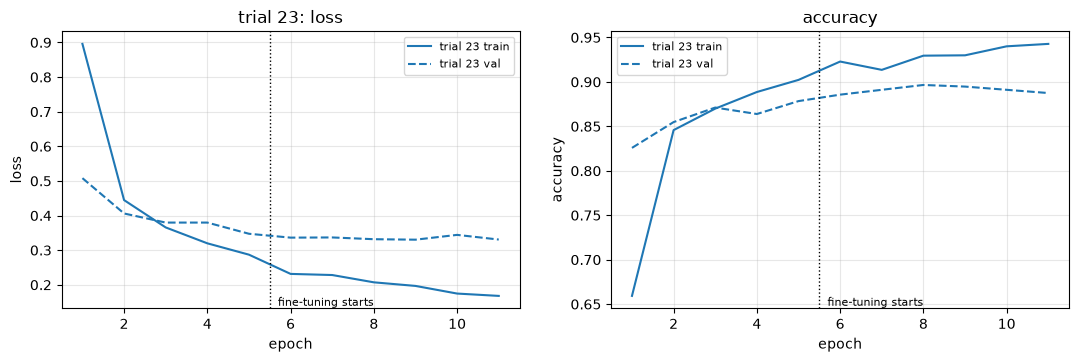

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
   12       30      adam    1e-06      5  True  1,532,805   0.886    0.336   113s
  

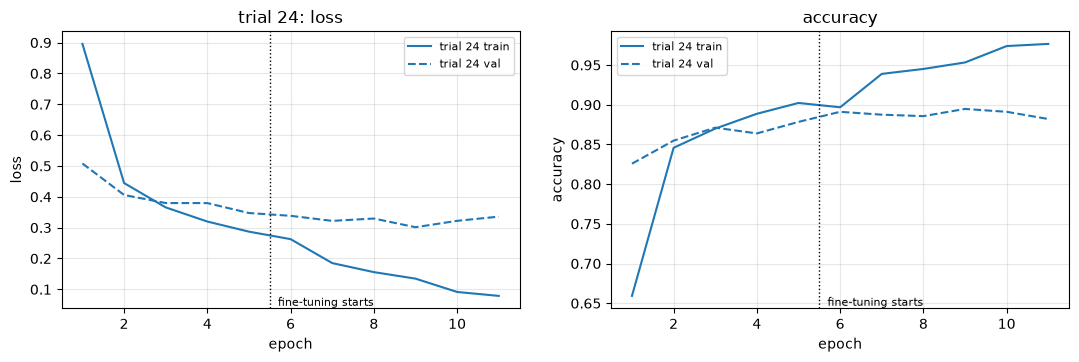

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
   11       30      adam    1e-06      9  True  1,532,805   0.886    0.333   202s
  

In [20]:
try_recipe(unfreeze=30, optimizer="adam", lr=3e-6, epochs=7, early_stopping=True)
try_recipe(unfreeze=30, optimizer="adam", lr=3e-5, epochs=7, early_stopping=True)

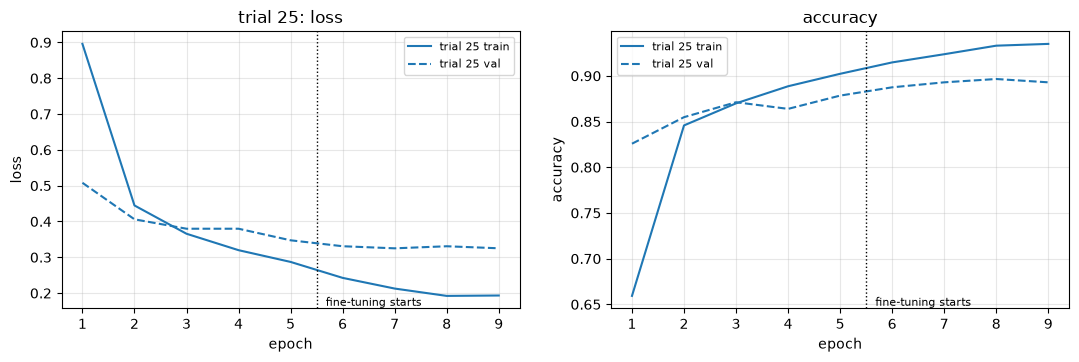

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
   15       50      adam    1e-05      5  True  1,861,509   0.889    0.316   116s
  

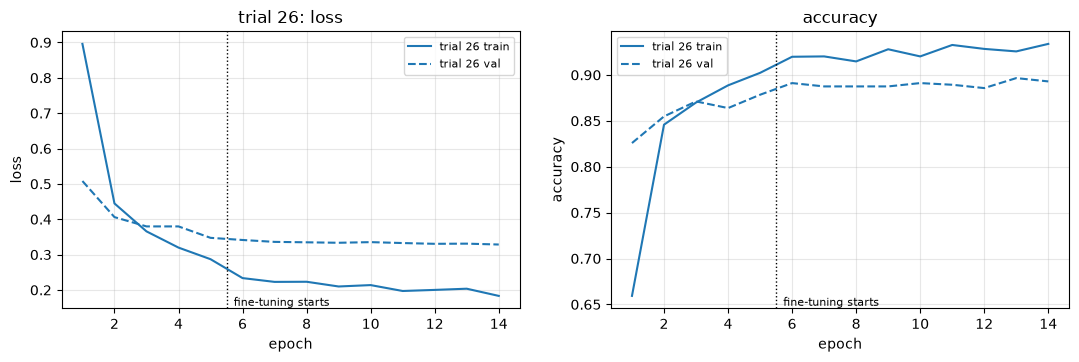

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
   14       40      adam    1e-05      5  True  1,687,941   0.889    0.316   116s
  

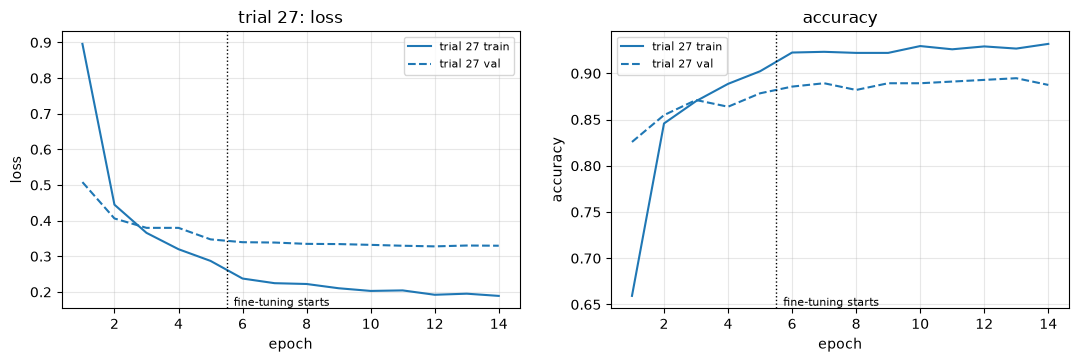

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s  ← your entry
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
   27       45      adam    1e-06      9  True  1,749,573   0.893    0.328   203s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
   13       30      adam    1e-05      9  True  1,532,805   0.891    0.321   206s
  

In [21]:
try_recipe(unfreeze=40, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)
try_recipe(unfreeze=35, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)
try_recipe(unfreeze=45, optimizer="adam", lr=1e-6, epochs=9, early_stopping=True)

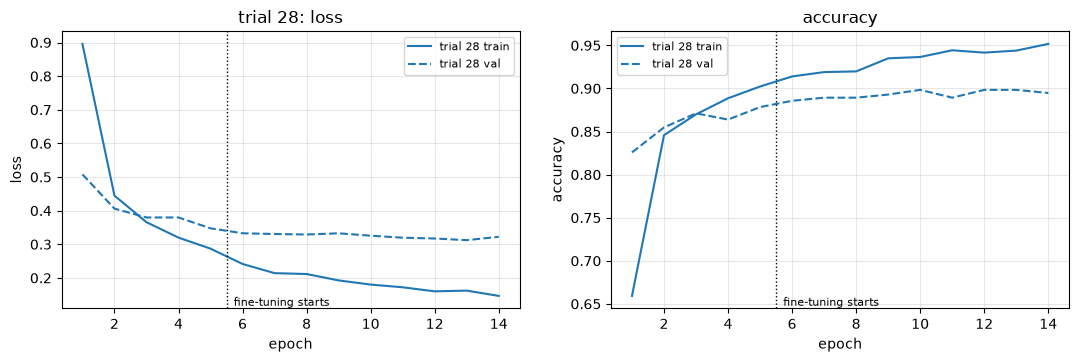

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s  ← your entry
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
   27       45      adam    1e-06      9  True  1,749,573   0.893    0.328   203s
    2       30      adam    1e-05      5  True  1,532,805   0.891    0.326   108s
  

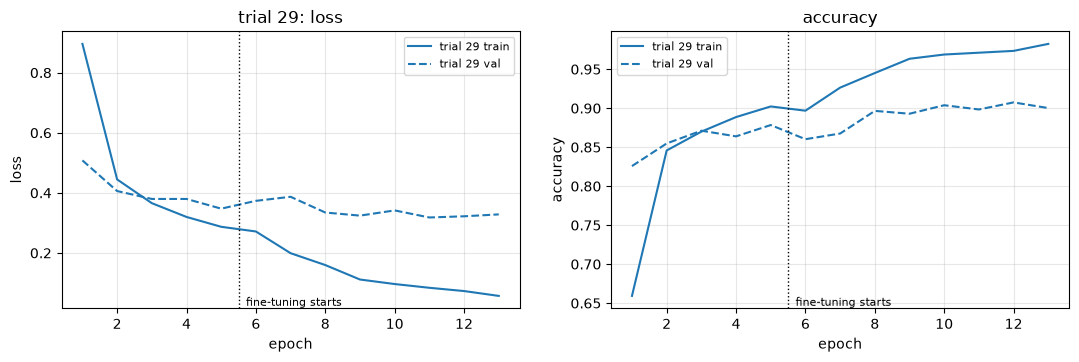

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s  ← your entry
   29       40      adam    3e-05      8  True  1,687,941   0.898    0.318   156s
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
   27       45      adam    1e-06      9  True  1,749,573   0.893    0.328   203s
  

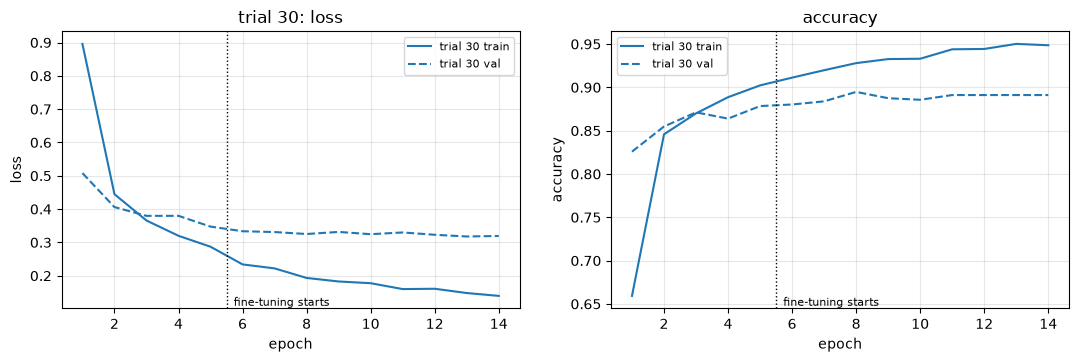

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s  ← your entry
   29       40      adam    3e-05      8  True  1,687,941   0.898    0.318   156s
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
   27       45      adam    1e-06      9  True  1,749,573   0.893    0.328   203s
  

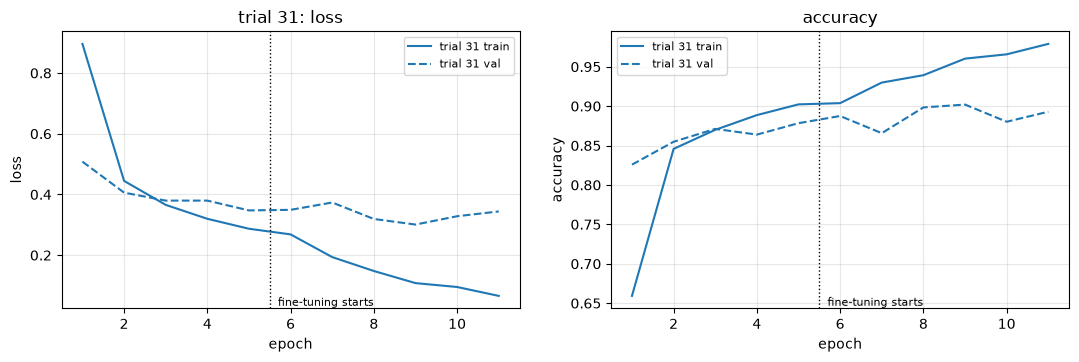

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   31       50      adam    3e-05      6  True  1,861,509   0.902    0.301   123s  ← your entry
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s
   29       40      adam    3e-05      8  True  1,687,941   0.898    0.318   156s
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
   26       35      adam    1e-06      9  True  1,631,301   0.893    0.329   165s
  

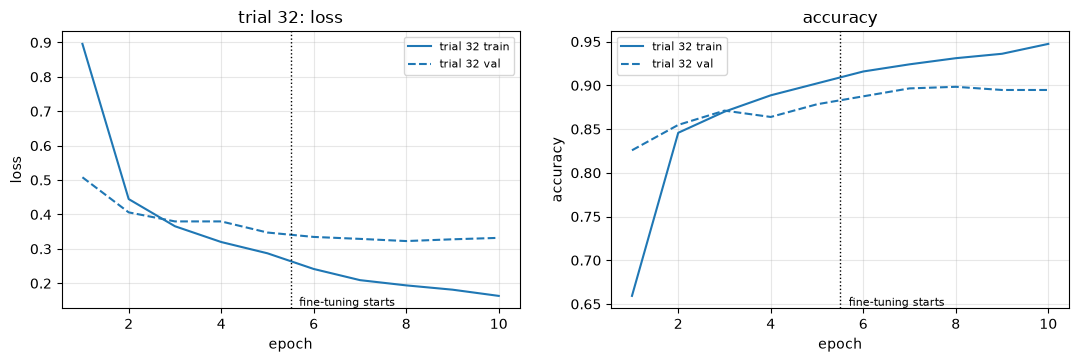

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   31       50      adam    3e-05      6  True  1,861,509   0.902    0.301   123s  ← your entry
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s
   29       40      adam    3e-05      8  True  1,687,941   0.898    0.318   156s
   32       60      adam    3e-06      5  True  1,962,117   0.898    0.323   112s
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
   25       40      adam    3e-06      4  True  1,687,941   0.893    0.325    89s
  

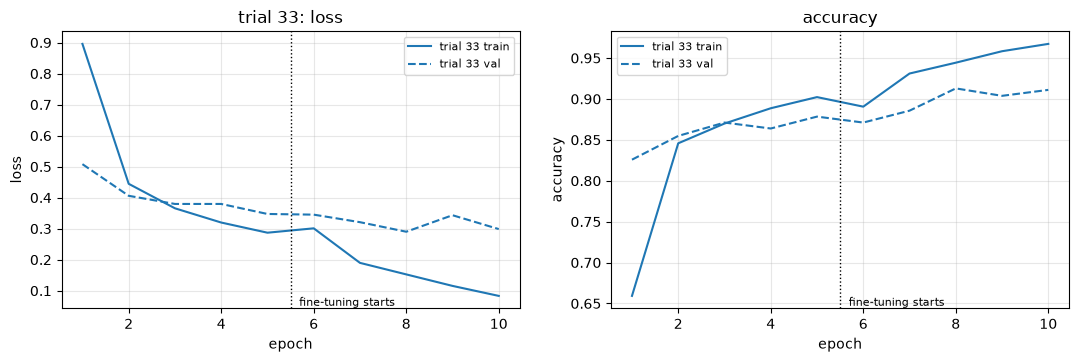

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
   33       60      adam    3e-05      5  True  1,962,117   0.913    0.290   109s  ← your entry
   31       50      adam    3e-05      6  True  1,861,509   0.902    0.301   123s
   28       40      adam    3e-06      9  True  1,687,941   0.898    0.312   179s
   29       40      adam    3e-05      8  True  1,687,941   0.898    0.318   156s
   32       60      adam    3e-06      5  True  1,962,117   0.898    0.323   112s
   17       40      adam    1e-06      9  True  1,687,941   0.897    0.331   166s
   16       60      adam    1e-05      9  True  1,962,117   0.895    0.304   213s
   19       60      adam    1e-06      9  True  1,962,117   0.895    0.328   196s
   23       30      adam    3e-06      6  True  1,532,805   0.895    0.330   152s
   24       30      adam    3e-05      6  True  1,532,805   0.895    0.301   163s
   18       50      adam    1e-06      9  True  1,861,509   0.893    0.328   175s
  

In [22]:
try_recipe(unfreeze=40, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)
try_recipe(unfreeze=40, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

try_recipe(unfreeze=50, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)
try_recipe(unfreeze=50, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

try_recipe(unfreeze=60, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)
try_recipe(unfreeze=60, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

c:\Users\Yelfia\Documents\DeepLearning\csc173-1s-2026\csc173-1s-2026-villanueva\activities\04\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


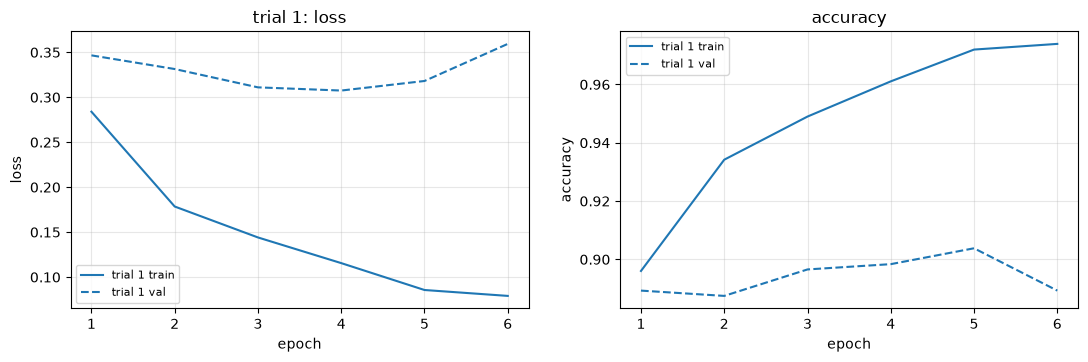

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       60      adam    3e-05      6  True  1,962,117   0.898    0.307   137s  ← your entry


In [ ]:
# Trial 33

try_recipe(unfreeze=60, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

# Kernel has been restarted, this serves as a rerun of the winning configuration during the experimentation phase

c:\Users\Yelfia\Documents\DeepLearning\csc173-1s-2026\csc173-1s-2026-villanueva\activities\04\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


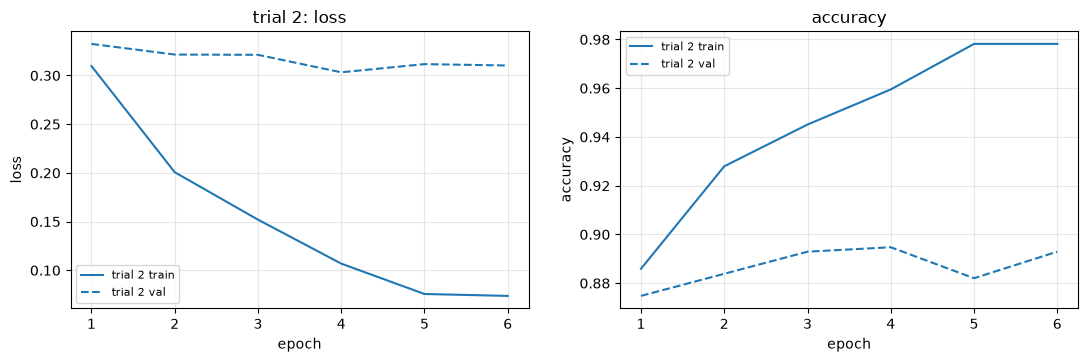

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       60      adam    3e-05      6  True  1,962,117   0.898    0.307   137s  ← your entry
    2       50      adam    3e-05      6  True  1,861,509   0.895    0.303   135s


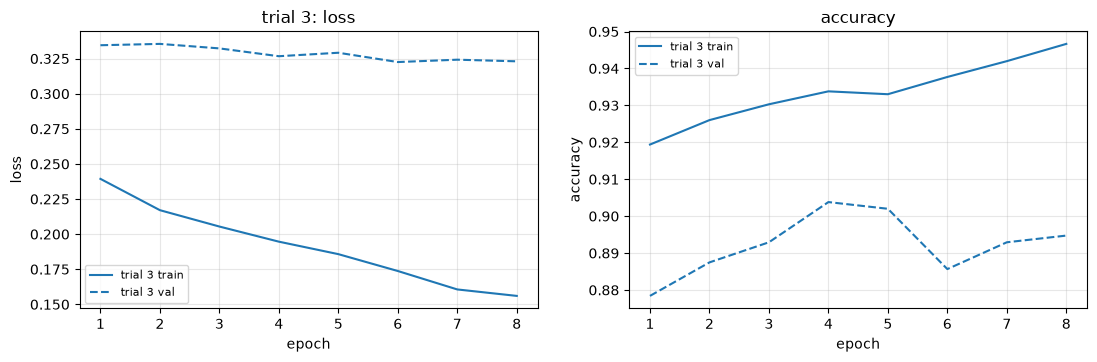

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       60      adam    3e-05      6  True  1,962,117   0.898    0.307   137s  ← your entry
    2       50      adam    3e-05      6  True  1,861,509   0.895    0.303   135s
    3       40      adam    3e-06      8  True  1,687,941   0.886    0.323   189s


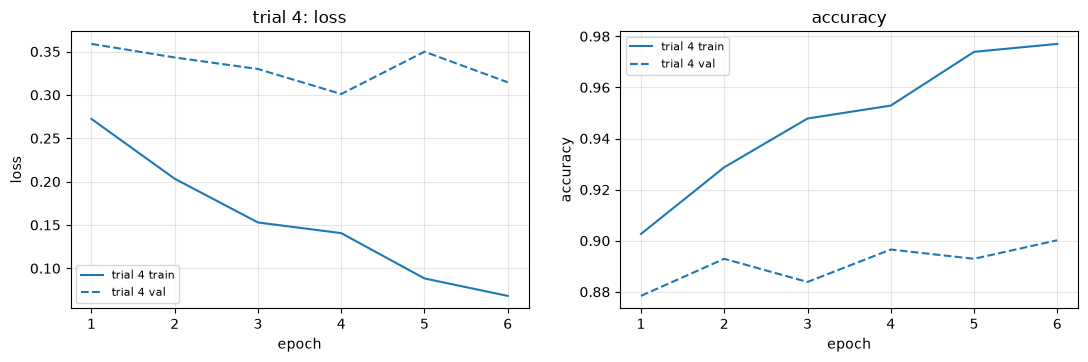

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       60      adam    3e-05      6  True  1,962,117   0.898    0.307   137s  ← your entry
    4       40      adam    3e-05      6  True  1,687,941   0.897    0.301   124s
    2       50      adam    3e-05      6  True  1,861,509   0.895    0.303   135s
    3       40      adam    3e-06      8  True  1,687,941   0.886    0.323   189s


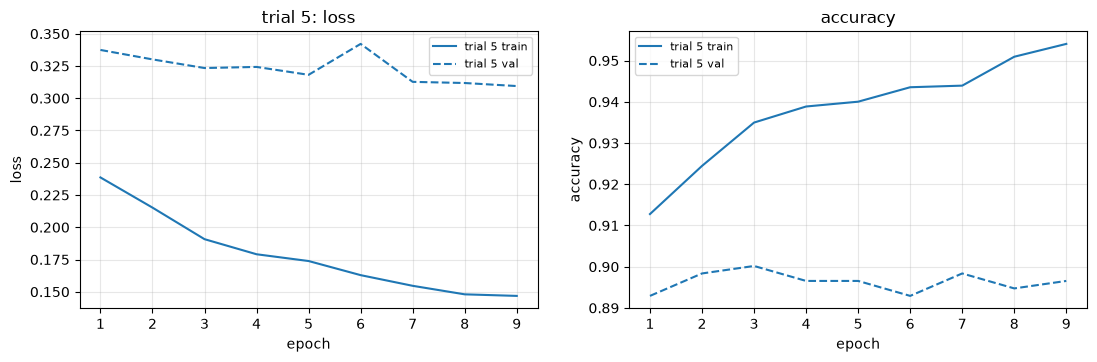

trial unfreeze optimizer       lr epochs early  trainable val_acc val_loss   time
    1       60      adam    3e-05      6  True  1,962,117   0.898    0.307   137s  ← your entry
    4       40      adam    3e-05      6  True  1,687,941   0.897    0.301   124s
    5       60      adam    3e-06      9  True  1,962,117   0.897    0.309   212s
    2       50      adam    3e-05      6  True  1,861,509   0.895    0.303   135s
    3       40      adam    3e-06      8  True  1,687,941   0.886    0.323   189s


In [14]:
# Trial 31
try_recipe(unfreeze=50, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

# Trial 28
try_recipe(unfreeze=40, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)

# Trial 29
try_recipe(unfreeze=40, optimizer="adam", lr=3e-5, epochs=9, early_stopping=True)

# Trial 32
try_recipe(unfreeze=60, optimizer="adam", lr=3e-6, epochs=9, early_stopping=True)

✍️ **Question 5.** (a) Paste your trial table. Which knob changed the validation accuracy the most? (b) For your **worst** trial, read its loss curve: what happened right after fine-tuning started, and why (use the words *learning rate*, *overfitting* or *underfitting*)? (c) Why does the challenge pick your entry by validation accuracy and not by test accuracy?

*Your answer:*

   
| Trial | Layers unfrozen | Optimizer | Learning rate | Epochs run | Early stopping | `val_acc` | `val_loss` |
|---:|---:|:---|---:|---:|:---:|---:|---:|
| **33** | **60** | **Adam** | **`3e-5`** | **5** | **Yes** | **0.913** | **0.290** |
| 31 | 50 | Adam | `3e-5` | 6 | Yes | 0.902 | 0.301 |
| 28 | 40 | Adam | `3e-6` | 9 | Yes | 0.898 | 0.312 |
| 29 | 40 | Adam | `3e-5` | 8 | Yes | 0.898 | 0.318 |
| 32 | 60 | Adam | `3e-6` | 5 | Yes | 0.898 | 0.323 |
| 17 | 40 | Adam | `1e-6` | 9 | Yes | 0.897 | 0.331 |
| 16 | 60 | Adam | `1e-5` | 9 | Yes | 0.895 | 0.304 |
| 19 | 60 | Adam | `1e-6` | 9 | Yes | 0.895 | 0.328 |
| 23 | 30 | Adam | `3e-6` | 6 | Yes | 0.895 | 0.330 |
| 24 | 30 | Adam | `3e-5` | 6 | Yes | 0.895 | 0.301 |
| 18 | 50 | Adam | `1e-6` | 9 | Yes | 0.893 | 0.328 |
| 25 | 40 | Adam | `3e-6` | 4 | Yes | 0.893 | 0.325 |
| 26 | 35 | Adam | `1e-6` | 9 | Yes | 0.893 | 0.329 |
| 27 | 45 | Adam | `1e-6` | 9 | Yes | 0.893 | 0.328 |
| 2 | 30 | Adam | `1e-5` | 5 | Yes | 0.891 | 0.326 |
| 13 | 30 | Adam | `1e-5` | 9 | Yes | 0.891 | 0.321 |
| 30 | 50 | Adam | `3e-6` | 9 | Yes | 0.891 | 0.318 |
| 14 | 40 | Adam | `1e-5` | 5 | Yes | 0.889 | 0.316 |
| 15 | 50 | Adam | `1e-5` | 5 | Yes | 0.889 | 0.316 |
| 11 | 30 | Adam | `1e-6` | 9 | Yes | 0.886 | 0.333 |
| 12 | 30 | Adam | `1e-6` | 5 | Yes | 0.886 | 0.336 |
| 21 | 50 | Adam | `1e-7` | 9 | Yes | 0.886 | 0.341 |
| 10 | 30 | Adam | `1e-6` | 6 | Yes | 0.884 | 0.334 |
| 20 | 40 | Adam | `1e-7` | 9 | Yes | 0.884 | 0.340 |
| 22 | 60 | Adam | `1e-7` | 9 | Yes | 0.884 | 0.340 |
| 7 | 30 | Adam | `1e-3` | 3 | No | 0.693 | 0.692 |
| 1 | 30 | Adam | `1e-3` | 7 | Yes | 0.577 | 0.863 |
| 4 | 50 | Adam | `1e-3` | 6 | Yes | 0.245 | 1.601 |
| 5 | 100 | Adam | `1e-3` | 6 | Yes | 0.245 | 1.605 |
| 8 | 30 | Adam | `1e-1` | 3 | Yes | 0.245 | 69.806 |
| 9 | 20 | Adam | `1e-3` | 3 | No | 0.245 | 1.640 |
| 6 | 30 | SGD | `1e-1` | 7 | Yes | 0.191 | 1455.083 |
| 3 | 30 | Adam | `1e-1` | 3 | Yes | 0.172 | 57.218 |

a) Exploring the learning rate knob has procured significant differences in results with the applied changes. As can be seen in Trials 1 and 2 which used the similar configurations: 30 unfrozen layers, 7 epochs run, and an enabled early stopping. Their learning rates however have been configured differently, with Trial 1 having 1e-3 and Trial having 1e-5. This raised the validation accuracy from 57.7% to 89.1%. Moreover, there have been significant changes incurred by changing the unfrozen layers. However, as can be observed in the table, their effects seem to vary with the configured learning rates. Some have affected validation accuracy directly, and some inversely.

b) Trial 3 performed the worst in our experiments. At the point wherein fine tuning began, validation loss spiked and validation accuracy dropped aggressively. This behavior may be attributed to its fast learning rate of 1e-1. Fast learning rates often introduce a lot of overshooting or overcompensating loss and thus would incur jagged spikes into its graphs. This is because large updates on pretrained layers may disrupt the useful features that were established in the base model. Moreover, we can also observe that at very early epochs, the model have reached 0 loss. This can be interpreted as a sever case of overfitting which explains its corresponsing inaccuracy. This similar behavior can be observed in Trials 7, 1, 4, 5, 8, 9, 6 which constitute the test runs with larger learning rates.

c) Validation sets are typically used for the purpose of development, in choosing the optimal model and its corresponding configurations such as the knobs adjusted in this competition: the unfrozen layers, epochs run, learning rate, and early stopping. As such, we are yet to use accuracy in this regard when tuning the model. If the test set has been used in the validation of the test tunings, the model might accustom its results to the pictures in the test set and may present the model's accuracy through an overly optimistic lens. As has been discussed before, the test set must remain invisible so as to not introduce image bias into the model. Only after tuning the model with the metric of validation accuracy, may we use the fresh images in the test set for test accuracy.

---
## 4. Results

### 4a. The official test score: run this cell ONCE

In [20]:
TEST_RUNS = globals().get("TEST_RUNS", 0) + 1      # counts how many times this cell has been run
entry_model = ENTRY["model"]
test_loss, test_acc = entry_model.evaluate(test_ds, verbose=0)    # TODO: evaluate entry_model on test_ds (verbose=0)
baseline = np.bincount(labels).max() / len(labels)
print(f"OFFICIAL TEST ACCURACY {test_acc:.3f} · entry = trial {ENTRY['trial']} · validation accuracy {ENTRY['val_acc']:.3f}"
      f" · always-the-largest-class baseline {baseline:.3f} · test runs: {TEST_RUNS}")
print("Check:", 0 <= test_acc <= 1 and TEST_RUNS == 1)

OFFICIAL TEST ACCURACY 0.917 · entry = trial 1 · validation accuracy 0.898 · always-the-largest-class baseline 0.245 · test runs: 1
Check: True


### 4b. Where does it go wrong?

The test photos your entry gets wrong with the most confidence.

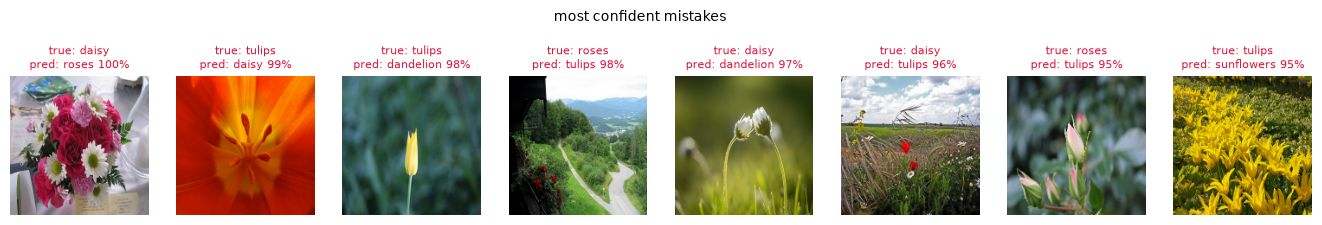

In [21]:
probs = entry_model.predict(test_ds, verbose=0)
y_true = labels[te_idx]
y_pred = probs.argmax(1)
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.1 * len(wrong), 2.8), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        img = load_image(paths[te_idx[i]], 0)[0].numpy()
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} {probs[i].max():.0%}", fontsize=8, color="crimson")
    plt.suptitle("most confident mistakes", fontsize=10); plt.show()

### 4c. The confusion matrix

Row = the true class, column = the predicted class. The diagonal holds the correct answers; every number off the diagonal is a mistake of one particular kind. Build it yourself, then read it.

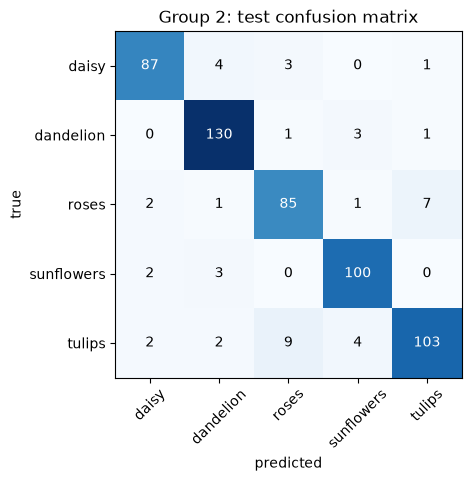

daisy       precision 0.935 · recall 0.916
dandelion   precision 0.929 · recall 0.963
roses       precision 0.867 · recall 0.885
sunflowers  precision 0.926 · recall 0.952
tulips      precision 0.920 · recall 0.858
most common mistake: tulips predicted as roses (9 photos)
Check: True


In [24]:
def confusion_matrix(y_true, y_pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1 # TODO
    return cm

cm = confusion_matrix(y_true, y_pred, NUM_CLASSES)
correct = cm.diagonal()
predicted_counts = cm.sum(axis=0)
true_counts = cm.sum(axis=1)
precision = np.divide(correct, predicted_counts, out=np.zeros(NUM_CLASSES), where=predicted_counts != 0) # TODO
recall = np.divide(correct, true_counts, out=np.zeros(NUM_CLASSES), where=true_counts != 0) # TODO

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45); ax.set_yticks(range(NUM_CLASSES), class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Group {GROUP}: test confusion matrix"); plt.show()
for c, name in enumerate(class_names):
    print(f"{name:11s} precision {precision[c]:.3f} · recall {recall[c]:.3f}")
off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"most common mistake: {class_names[i]} predicted as {class_names[j]} ({off[i, j]} photos)")
print("Check:", cm.sum() == len(y_true) and np.trace(cm) == (y_true == y_pred).sum() and np.allclose(recall, [np.mean(y_pred[y_true == c] == c) for c in range(NUM_CLASSES)]))

### 4d. Your leaderboard line

The Reporter copies this line to the **leaderboard**.

In [ ]:
r = ENTRY
result_line = (f"Group {GROUP} | TEST {test_acc:.3f} | val {r['val_acc']:.3f} | unfreeze {r['unfreeze']} | {r['optimizer']} lr {r['lr']:g} | "
               f"{r['epochs_run']} epochs | early stop {r['early_stopping']} | trainable {r['trainable']:,} | trials {len(TRIALS)} | test runs {TEST_RUNS}")
print(result_line)

Group 2 | TEST 0.917 | val 0.898 | unfreeze 60 | adam lr 3e-05 | 6 epochs | early stop True | trainable 1,962,117 | trials 5 | test runs 1


: 

✍️ **Question 6: reading the confusion matrix.** (a) Is your test accuracy close to your validation accuracy? What would a large gap mean? (b) Which pair of classes is confused most often, and in which direction (true → predicted)? Look at the photos in 4b: is it a reasonable mistake for a person too? (c) Pick the class with the lowest precision and the class with the lowest recall. In one sentence each, say what that number means for a user of the app ("when the app says *rose* ..." / "of all the real roses ...").

*Your answer:*

a) close. 
0.917 | val 0.898
large gap = overfitting/underfitting

b) tulips and roses. first image looks like a bouqet of roses mixed with daisies. reasonable mistake for a person too. The same applies to the mistakes on dandelion classifications

c) lowest precision rose; lowest recall roses

daisy       precision 0.935 · recall 0.916
dandelion   precision 0.929 · recall 0.963
roses       precision 0.867 · recall 0.885
sunflowers  precision 0.926 · recall 0.952
tulips      precision 0.920 · recall 0.858


---
## 5. Leaderboard reveal 🏆

The instructor sorts the leaderboard by test accuracy. The **top 3** Reporters give a **45-second share-out**: your recipe, your best trial, and one thing you learned from a trial that failed. Fill in the top 5 while you listen.

| Rank | Group | Test acc | Val acc | unfreeze | optimizer, lr | epochs | early stop |
|---|---|---|---|---|---|---|---|
| 1 | | | | | | | |
| 2 | | | | | | | |
| 3 | | | | | | | |
| 4 | | | | | | | |
| 5 | | | | | | | |

✍️ **Question 7.** (a) What did the top recipes have in common? Was the gap between first and fifth bigger or smaller than the gap between two groups' validation and test accuracies (i.e. is the winner clearly better, or partly lucky)? (b) A friend has 300 photos of 4 kinds of Philippine mangoes. Using the leaderboard, write their recipe in 3 steps: what to freeze, which optimizer and learning rate, in what order.

*Your answer:*

### 5b. Curve-reading gallery

These six plots are the **training (solid) and validation (dashed) loss** of six reference recipes, shown in a **random order**. The dotted line marks where stage 2 starts (for the run trained from scratch, the line is only a marker: it had no stage 1).

| Recipe | What was done |
|---|---|
| A | stage 1, then top 30 layers, Adam $10^{-5}$ |
| B | stage 1, then all layers, Adam $10^{-5}$ |
| C | stage 1, then all layers, Adam $10^{-3}$ |
| D | stage 1, then top 30 layers, SGD + momentum $10^{-5}$ |
| E | like A, but with only 10 training photos per class |
| F | no pretrained weights, all layers, Adam $10^{-3}$, 10 epochs |

@@GALLERY@@

✍️ **Question 8.** For each run, (a) write one diagnosis: *good fit*, *overfitting*, *underfitting / learning too slowly*, or *a learning rate too big, so the pretrained features were damaged*; (b) say which recipe (A to F) it is; (c) point to the feature of the curve that told you (for example "the validation loss rises after epoch 4 while the training loss keeps falling").

*Your answer:*

### Group contributions

One line per member: your role and one specific thing you did or caught. Groups that list an error and how they fixed it get credit for it.

*Driver:*

*Navigator:*

*Experimenter:*

*Reporter:*

---
## Before you submit

Every `# TODO` is filled in, every `Check:` prints `True`, the notebook has been run from top to bottom (*Runtime → Restart and run all* if you have time; otherwise make sure the outputs match the code), and every ✍️ question is answered. Submit **one notebook per group**, named `Group<N>_FineTuning.ipynb`.